# Epileptic Seizure Prediction - Machine Learning

Topic: Machine Learning for Predicting Epileptic Seizures

Dataset: `synthetic_seizure_demo_100_patients.csv` (100 patients, balanced)

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, confusion_matrix, classification_report)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

plt.rcParams['figure.figsize'] = (6,4)

## 1. Data Loading

In [2]:
df = pd.read_csv('synthetic_seizure_demo_100_patients.csv')
print('Shape:', df.shape)
df.head()

Shape: (100, 10)


,patient_id,EEG_mean,EEG_std,EEG_delta_power,EEG_theta_power,EEG_alpha_power,EEG_beta_power,ECG_heart_rate_bpm,ECG_RMSSD_ms,seizure_label
0,P001,-0.0694,31.290,0.397,0.202,0.098,0.086,94.0,32.7,1
1,P002,0.1036,19.864,0.319,0.313,0.252,0.202,66.1,37.6,0
2,P003,-0.0573,21.021,0.478,0.283,0.201,0.184,93.4,39.0,1
3,P004,-0.0148,19.884,0.290,0.081,0.150,0.077,62.0,46.8,0
4,P005,-0.1358,20.109,0.456,0.214,0.346,0.105,71.5,30.6,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   patient_id          100 non-null    str    
 1   EEG_mean            100 non-null    float64
 2   EEG_std             100 non-null    float64
 3   EEG_delta_power     100 non-null    float64
 4   EEG_theta_power     100 non-null    float64
 5   EEG_alpha_power     100 non-null    float64
 6   EEG_beta_power      100 non-null    float64
 7   ECG_heart_rate_bpm  100 non-null    float64
 8   ECG_RMSSD_ms        100 non-null    float64
 9   seizure_label       100 non-null    int64  
dtypes: float64(8), int64(1), str(1)
memory usage: 8.3 KB


In [4]:
df.describe()

,EEG_mean,EEG_std,EEG_delta_power,EEG_theta_power,EEG_alpha_power,EEG_beta_power,ECG_heart_rate_bpm,ECG_RMSSD_ms,seizure_label
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,-0.001600,24.682690,0.346110,0.281720,0.230060,0.148280,81.650000,37.883000,0.500000
std,0.139851,6.081064,0.127928,0.105678,0.095624,0.067678,14.593118,13.940436,0.502519
min,-0.350000,10.544000,0.010000,0.081000,0.033000,0.010000,49.200000,7.100000,0.000000
25%,-0.091625,20.133000,0.276000,0.211000,0.173000,0.101500,72.875000,28.450000,0.000000
50%,-0.014400,24.734500,0.358500,0.277500,0.224000,0.148000,82.950000,38.350000,0.500000
75%,0.077700,28.490500,0.446750,0.350000,0.298000,0.184000,90.925000,46.425000,1.000000
max,0.437100,38.913000,0.669000,0.648000,0.509000,0.373000,113.100000,71.000000,1.000000


In [5]:
df['seizure_label'].value_counts()

seizure_label
1    50
0    50
Name: count, dtype: int64

In [6]:
# Missing values
df.isnull().sum()

patient_id            0
EEG_mean              0
EEG_std               0
EEG_delta_power       0
EEG_theta_power       0
EEG_alpha_power       0
EEG_beta_power        0
ECG_heart_rate_bpm    0
ECG_RMSSD_ms          0
seizure_label         0
dtype: int64

## 2. Feature Engineering & Selection

In [7]:
# Separate features and target
X = df.drop(['patient_id', 'seizure_label'], axis=1)
y = df['seizure_label']
print('Features:', X.columns.tolist())
print('Shape X,y:', X.shape, y.shape)

Features: ['EEG_mean', 'EEG_std', 'EEG_delta_power', 'EEG_theta_power', 'EEG_alpha_power', 'EEG_beta_power', 'ECG_heart_rate_bpm', 'ECG_RMSSD_ms']
Shape X,y: (100, 8) (100,)


In [8]:
# Correlation with target
corr = df.drop('patient_id', axis=1).corr()['seizure_label'].sort_values(ascending=False)
corr

seizure_label         1.000000
ECG_heart_rate_bpm    0.609230
EEG_std               0.554322
EEG_theta_power       0.383840
EEG_delta_power       0.269862
EEG_mean              0.024262
EEG_beta_power       -0.094448
ECG_RMSSD_ms         -0.330845
EEG_alpha_power      -0.412426
Name: seizure_label, dtype: float64

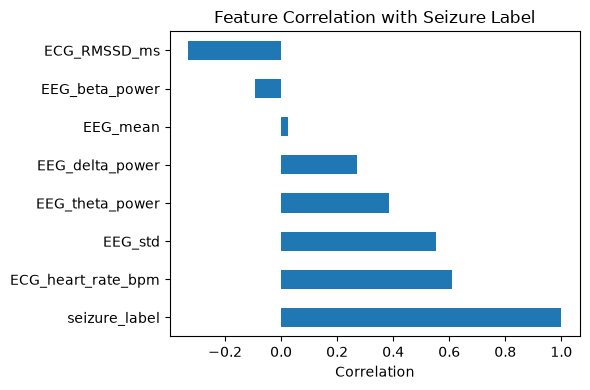

In [9]:
corr[:-1].plot(kind='barh', title='Feature Correlation with Seizure Label')
plt.xlabel('Correlation'); plt.tight_layout(); plt.show()

## 3. Train-Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(80, 8) (20, 8)


In [11]:
# Scale features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 4. Model Training & Evaluation

In [12]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM (RBF)': SVC(probability=True, random_state=42)
}

results = []
for name, model in models.items():
    # Train
    if name == 'SVM (RBF)':
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        y_proba = model.predict_proba(X_test_s)[:,1] if hasattr(model, 'predict_proba') else None
    else:
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        y_proba = model.predict_proba(X_test_s)[:,1] if hasattr(model, 'predict_proba') else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc
    })
    
    print(f'\n=== {name} ===')
    print(classification_report(y_test, y_pred))
    print('Confusion Matrix:')
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results)
results_df


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.91      1.00      0.95        10
           1       1.00      0.90      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20

Confusion Matrix:
[[10  0]
 [ 1  9]]



=== Random Forest ===
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        10
           1       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20

Confusion Matrix:
[[9 1]
 [1 9]]



=== SVM (RBF) ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20

Confusion Matrix:
[[10  0]
 [ 0 10]]


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.95,1.0,0.9,0.947368,0.980
1,Random Forest,0.90,0.9,0.9,0.900000,0.905
2,SVM (RBF),1.00,1.0,1.0,1.000000,1.000


## 5. Cross Validation

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
for name, model in models.items():
    if 'SVM' in name:
        scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring='accuracy')
    else:
        scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring='accuracy')
    cv_results[name] = scores
    print(f'{name}: {scores.mean():.4f} ± {scores.std():.4f}')

Logistic Regression: 0.9375 ± 0.0559


Random Forest: 0.8750 ± 0.0559
SVM (RBF): 0.9250 ± 0.0612


## 6. Feature Importance (Random Forest)

In [14]:
rf = models['Random Forest']
feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)
feat_imp

,Feature,Importance
1,EEG_std,0.267366
6,ECG_heart_rate_bpm,0.209729
4,EEG_alpha_power,0.135025
7,ECG_RMSSD_ms,0.103059
3,EEG_theta_power,0.091307
0,EEG_mean,0.082296
2,EEG_delta_power,0.056761
5,EEG_beta_power,0.054457


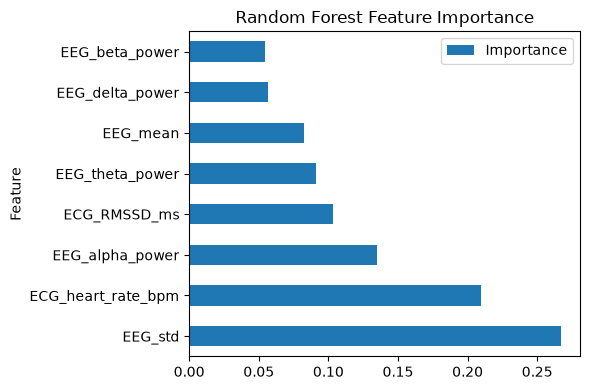

In [15]:
feat_imp.plot(kind='barh', x='Feature', y='Importance', title='Random Forest Feature Importance')
plt.tight_layout(); plt.show()

## 7. Conclusion

- Dataset: 100 samples, balanced (50 seizure, 50 non-seizure)
- Models tested: Logistic Regression, Random Forest, SVM
- Evaluate using Accuracy, Precision, Recall, F1, ROC-AUC + CV
- Feature importance shows key EEG/ECG contributors

**Note:** Small dataset - results need validation on larger real data.